<a href="https://colab.research.google.com/github/ikraugurlu/eem4011-proje/blob/main/eem4011_proje.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install -q pyedflib
from google.colab import drive
drive.mount('/content/drive')

import os, urllib.request
import pyedflib

klasor = '/content/drive/MyDrive/eegmmidb'
os.makedirs(klasor, exist_ok=True)

kisiler = [f'S{i:03d}' for i in range(1, 21)]
kosular = ['R04', 'R08', 'R12']

gecerli_dosyalar = []
toplam_deneme = 0

for kisi in kisiler:
    for kosu in kosular:
        ad = f'{kisi}{kosu}.edf'
        link = f'https://physionet-open.s3.amazonaws.com/eegmmidb/1.0.0/{kisi}/{ad}'
        yol = os.path.join(klasor, ad)

        if os.path.exists(yol):
            if os.path.getsize(yol) > 2_000_000:
                print(ad, 'zaten var, atlandı')
            else:
                os.remove(yol)
                print(ad, 'eksikti, silindi')
        if not os.path.exists(yol):
            urllib.request.urlretrieve(link, yol + '.part')
            os.rename(yol + '.part', yol)
            print(ad, 'indirildi')

        with pyedflib.EdfReader(yol) as e:
            etiket = [l.strip('.') for l in e.getSignalLabels()]
            kanallar_var = all(k in etiket for k in ['C3', 'Cz', 'C4'])
            if not kanallar_var:
                print(ad, '| C3/Cz/C4 eksik, atlandı')
                continue
            fs = int(e.getSampleFrequency(etiket.index('C3')))
            onset, sure, kod = e.readAnnotations()

        deneme = sum(1 for k in kod if k in ('T1', 'T2'))
        if fs != 160:
            print(ad, '| fs =', fs, '-> 160 değil, atlandı')
            continue

        print(ad, '| fs =', fs, '| C3/Cz/C4 var:', kanallar_var, '| T1+T2 =', deneme)
        gecerli_dosyalar.append(yol)
        toplam_deneme += deneme

print('Toplam dosya:', len(gecerli_dosyalar))
print('Toplam deneme:', toplam_deneme)

Mounted at /content/drive
S001R04.edf zaten var, atlandı
S001R04.edf | fs = 160 | C3/Cz/C4 var: True | T1+T2 = 15
S001R08.edf zaten var, atlandı
S001R08.edf | fs = 160 | C3/Cz/C4 var: True | T1+T2 = 15
S001R12.edf zaten var, atlandı
S001R12.edf | fs = 160 | C3/Cz/C4 var: True | T1+T2 = 15
S002R04.edf zaten var, atlandı
S002R04.edf | fs = 160 | C3/Cz/C4 var: True | T1+T2 = 15
S002R08.edf zaten var, atlandı
S002R08.edf | fs = 160 | C3/Cz/C4 var: True | T1+T2 = 15
S002R12.edf zaten var, atlandı
S002R12.edf | fs = 160 | C3/Cz/C4 var: True | T1+T2 = 15
S003R04.edf zaten var, atlandı
S003R04.edf | fs = 160 | C3/Cz/C4 var: True | T1+T2 = 15
S003R08.edf zaten var, atlandı
S003R08.edf | fs = 160 | C3/Cz/C4 var: True | T1+T2 = 15
S003R12.edf zaten var, atlandı
S003R12.edf | fs = 160 | C3/Cz/C4 var: True | T1+T2 = 15
S004R04.edf zaten var, atlandı
S004R04.edf | fs = 160 | C3/Cz/C4 var: True | T1+T2 = 15
S004R08.edf zaten var, atlandı
S004R08.edf | fs = 160 | C3/Cz/C4 var: True | T1+T2 = 15
S004R1

In [3]:
import os
import numpy as np
import pandas as pd
import pyedflib
from scipy.signal import butter, sosfiltfilt

klasor = '/content/drive/MyDrive/eegmmidb'
kisiler = [f'S{i:03d}' for i in range(1, 21)]
kosular = ['R04', 'R08', 'R12']

FS = 160
MU = (8, 13)
GOREV = (0.5, 4.0)
DINLENME = (-3.0, 0.0)

sos = butter(4, MU, btype='bandpass', fs=FS, output='sos')

def guc(x, bas, son):
    return np.mean(x[bas:son] ** 2)

satirlar = []
atlanan = 0
for kisi in kisiler:
    for kosu in kosular:
        yol = os.path.join(klasor, f'{kisi}{kosu}.edf')
        with pyedflib.EdfReader(yol) as e:
            etiket = [l.strip('.') for l in e.getSignalLabels()]
            c3 = e.readSignal(etiket.index('C3'))
            c4 = e.readSignal(etiket.index('C4'))
            onset, sure, kod = e.readAnnotations()
        c3f = sosfiltfilt(sos, c3)
        c4f = sosfiltfilt(sos, c4)

        for t, k in zip(onset, kod):
            if k not in ('T1', 'T2'):
                continue
            i0 = int(round(t * FS))
            g_bas, g_son = i0 + int(GOREV[0] * FS), i0 + int(GOREV[1] * FS)
            d_bas, d_son = i0 + int(DINLENME[0] * FS), i0 + int(DINLENME[1] * FS)
            if d_bas < 0 or g_son > len(c3f):
                atlanan += 1
                continue
            erd_c3 = 10 * np.log10(guc(c3f, g_bas, g_son) / guc(c3f, d_bas, d_son))
            erd_c4 = 10 * np.log10(guc(c4f, g_bas, g_son) / guc(c4f, d_bas, d_son))
            li = erd_c3 - erd_c4
            gercek = 'sol' if k == 'T1' else 'sağ'
            tahmin = 'sol' if li > 0 else 'sağ'
            satirlar.append({'kisi': kisi, 'kosu': kosu, 'gercek': gercek,
                             'erd_c3': erd_c3, 'erd_c4': erd_c4, 'li': li,
                             'tahmin': tahmin, 'dogru': gercek == tahmin})

denemeler = pd.DataFrame(satirlar)
print('Kullanılan deneme:', len(denemeler), '| Atlanan deneme:', atlanan)

kisi_satirlari = []
for kisi, g in denemeler.groupby('kisi'):
    kisi_satirlari.append({
        'kisi': kisi,
        'deneme': len(g),
        'dogruluk': g['dogru'].mean(),
        'sol_dogru': g.loc[g['gercek'] == 'sol', 'dogru'].mean(),
        'sag_dogru': g.loc[g['gercek'] == 'sağ', 'dogru'].mean(),
        'sag_deme': (g['tahmin'] == 'sağ').mean(),
    })
tablo = pd.DataFrame(kisi_satirlari).set_index('kisi')
print(tablo.round(3).to_string())

sutunlar = ['dogruluk', 'sol_dogru', 'sag_dogru', 'sag_deme']
print('\nOrtalama ± std (ddof=1) ve medyan:')
for s in sutunlar:
    print(f"{s:10s}: {tablo[s].mean():.3f} ± {tablo[s].std(ddof=1):.3f} | medyan {tablo[s].median():.3f}")

print('\n2x2 sayım tablosu (satır: gerçek, sütun: tahmin):')
print(pd.crosstab(denemeler['gercek'], denemeler['tahmin'], margins=True, margins_name='Toplam'))

Kullanılan deneme: 900 | Atlanan deneme: 0
      deneme  dogruluk  sol_dogru  sag_dogru  sag_deme
kisi                                                  
S001      45     0.489      0.391      0.591     0.600
S002      45     0.578      0.391      0.773     0.689
S003      45     0.444      0.391      0.500     0.556
S004      45     0.600      0.609      0.591     0.489
S005      45     0.533      0.667      0.417     0.378
S006      45     0.556      0.708      0.381     0.333
S007      45     0.600      0.609      0.591     0.489
S008      45     0.489      0.409      0.565     0.578
S009      45     0.467      0.625      0.286     0.333
S010      45     0.600      0.583      0.619     0.511
S011      45     0.644      0.609      0.682     0.533
S012      45     0.600      0.524      0.667     0.578
S013      45     0.489      0.435      0.545     0.556
S014      45     0.511      0.545      0.478     0.467
S015      45     0.578      0.522      0.636     0.556
S016      45     0.556

In [ ]:
rng = np.random.default_rng(0)
B = 2000

dogruluklar = tablo['dogruluk'].to_numpy()
n_kisi = len(dogruluklar)

boot_ort = np.empty(B)
for b in range(B):
    secilen = rng.integers(0, n_kisi, size=n_kisi)
    boot_ort[b] = dogruluklar[secilen].mean()

alt, ust = np.percentile(boot_ort, [2.5, 97.5])

print('Kişi sayısı:', n_kisi, '| Bootstrap tekrarı:', B, '| Tohum: 0')
print(f'Ortalama doğruluk: {dogruluklar.mean():.3f}')
print(f'%95 güven aralığı: [{alt:.3f}, {ust:.3f}]')
print(f'Bootstrap ortalamalarının 0.50 veya altında kalma oranı: {(boot_ort <= 0.5).mean():.4f}')

Kişi sayısı: 20 | Bootstrap tekrarı: 2000 | Tohum: 0
Ortalama doğruluk: 0.542
%95 güven aralığı: [0.519, 0.566]
Bootstrap ortalamalarının 0.50 veya altında kalma oranı: 0.0005


En düşük doğruluklu 3 kişi: ['S003', 'S009', 'S018']


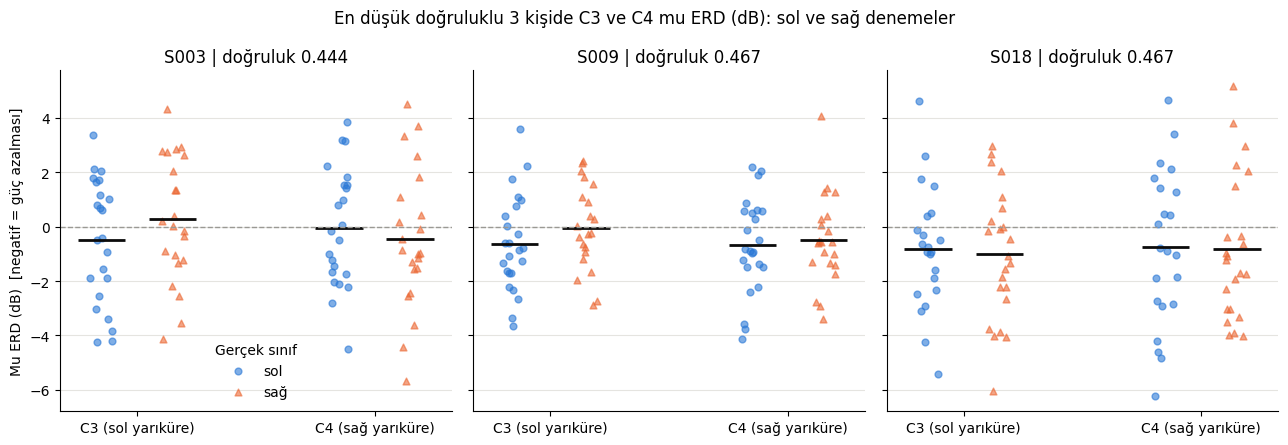

             erd_c3  erd_c4    li
kisi gercek                      
S003 sağ       0.28   -0.45  0.74
     sol      -0.50   -0.03 -0.46
S009 sağ      -0.04   -0.50  0.46
     sol      -0.63   -0.68  0.04
S018 sağ      -1.01   -0.84 -0.17
     sol      -0.81   -0.76 -0.04


In [ ]:
import matplotlib.pyplot as plt

en_kotu = tablo['dogruluk'].nsmallest(3).index.tolist()
print('En düşük doğruluklu 3 kişi:', en_kotu)

RENK = {'sol': '#2a78d6', 'sağ': '#eb6834'}
ISARET = {'sol': 'o', 'sağ': '^'}
KAYMA = {'sol': -0.15, 'sağ': 0.15}
rng_j = np.random.default_rng(1)

fig, eksenler = plt.subplots(1, 3, figsize=(13, 4.5), sharey=True)
for ax, kisi in zip(eksenler, en_kotu):
    g = denemeler[denemeler['kisi'] == kisi]
    for xi, kanal in enumerate(['erd_c3', 'erd_c4']):
        for sinif in ['sol', 'sağ']:
            y = g.loc[g['gercek'] == sinif, kanal].to_numpy()
            x = xi + KAYMA[sinif] + rng_j.uniform(-0.05, 0.05, len(y))
            ax.scatter(x, y, s=24, color=RENK[sinif], marker=ISARET[sinif], alpha=0.6,
                       label=sinif if xi == 0 else None)
            ax.hlines(y.mean(), xi + KAYMA[sinif] - 0.1, xi + KAYMA[sinif] + 0.1,
                      color='#0b0b0b', linewidth=2)
    ax.axhline(0, color='#9a9994', linewidth=1, linestyle='--')
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['C3 (sol yarıküre)', 'C4 (sağ yarıküre)'])
    ax.set_title(f"{kisi} | doğruluk {tablo.loc[kisi, 'dogruluk']:.3f}")
    ax.grid(axis='y', color='#e5e4e0', linewidth=0.8)
    ax.set_axisbelow(True)
    for kenar in ['top', 'right']:
        ax.spines[kenar].set_visible(False)

eksenler[0].set_ylabel('Mu ERD (dB)  [negatif = güç azalması]')
eksenler[0].legend(title='Gerçek sınıf', frameon=False)
fig.suptitle('En düşük doğruluklu 3 kişide C3 ve C4 mu ERD (dB): sol ve sağ denemeler')
fig.tight_layout()
fig.savefig('/content/drive/MyDrive/sekil_en_kotu3_erd.png', dpi=150)
plt.show()

ozet = (denemeler[denemeler['kisi'].isin(en_kotu)]
        .groupby(['kisi', 'gercek'])[['erd_c3', 'erd_c4', 'li']].mean())
print(ozet.round(2).to_string())

n = 45 için eşik k: 30

45 denemede en az 30 doğru olasılığı P(X >= 30 | p):
  p = 0.50: 0.018
  p = 0.55: 0.076
  p = 0.60: 0.225
  p = 0.65: 0.475
  p = 0.70: 0.746
  p = 0.75: 0.925
  p = 0.80: 0.989
  p = 0.85: 0.999
  p = 0.90: 1.000


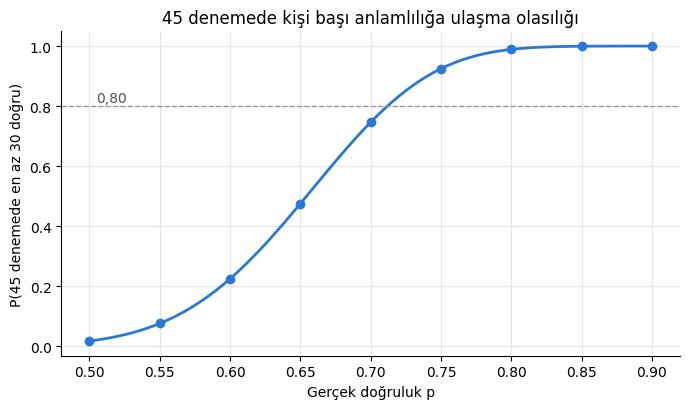


p = 0.65 için:
  n =  45 | eşik k =  30 | P(X >= k | p) = 0.475 | süre ≈ 6 dk
  n =  60 | eşik k =  39 | P(X >= k | p) = 0.559 | süre ≈ 8 dk
  n =  75 | eşik k =  47 | P(X >= k | p) = 0.710 | süre ≈ 10 dk
  n =  90 | eşik k =  55 | P(X >= k | p) = 0.812 | süre ≈ 12 dk
  n = 105 | eşik k =  64 | P(X >= k | p) = 0.835 | süre ≈ 14 dk
  n = 120 | eşik k =  72 | P(X >= k | p) = 0.892 | süre ≈ 16 dk
  n = 135 | eşik k =  80 | P(X >= k | p) = 0.930 | süre ≈ 18 dk
  n = 150 | eşik k =  88 | P(X >= k | p) = 0.955 | süre ≈ 20 dk
  n = 165 | eşik k =  96 | P(X >= k | p) = 0.971 | süre ≈ 22 dk
  n = 180 | eşik k = 104 | P(X >= k | p) = 0.982 | süre ≈ 24 dk
  n = 195 | eşik k = 112 | P(X >= k | p) = 0.988 | süre ≈ 26 dk
  n = 210 | eşik k = 120 | P(X >= k | p) = 0.992 | süre ≈ 28 dk
  n = 225 | eşik k = 128 | P(X >= k | p) = 0.995 | süre ≈ 30 dk
  n = 240 | eşik k = 136 | P(X >= k | p) = 0.997 | süre ≈ 32 dk
  n = 255 | eşik k = 144 | P(X >= k | p) = 0.998 | süre ≈ 34 dk
  n = 270 | eşik k = 152 |

In [ ]:
from scipy.stats import binom
import numpy as np
import matplotlib.pyplot as plt

def esik_k(n, alfa=0.025):
    k = np.arange(0, n + 1)
    sf = binom.sf(k - 1, n, 0.5)
    return int(k[sf <= alfa][0])

print('n = 45 için eşik k:', esik_k(45))

p_degerleri = np.round(np.arange(0.50, 0.901, 0.05), 2)
print('\n45 denemede en az 30 doğru olasılığı P(X >= 30 | p):')
for p in p_degerleri:
    print(f'  p = {p:.2f}: {binom.sf(29, 45, p):.3f}')

p_ince = np.linspace(0.50, 0.90, 81)
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(p_ince, binom.sf(29, 45, p_ince), color='#2a78d6', linewidth=2)
ax.scatter(p_degerleri, binom.sf(29, 45, p_degerleri), color='#2a78d6', s=36, zorder=3)
ax.axhline(0.80, color='#9a9994', linestyle='--', linewidth=1)
ax.text(0.505, 0.815, '0,80', color='#52514e')
ax.set_xlabel('Gerçek doğruluk p')
ax.set_ylabel('P(45 denemede en az 30 doğru)')
ax.set_title('45 denemede kişi başı anlamlılığa ulaşma olasılığı')
ax.grid(color='#e5e4e0', linewidth=0.8)
ax.set_axisbelow(True)
for kenar in ['top', 'right']:
    ax.spines[kenar].set_visible(False)
fig.tight_layout()
fig.savefig('/content/drive/MyDrive/sekil_binom_guc.png', dpi=150)
plt.show()

n_degerleri = list(range(45, 301, 15))
for p in [0.65, 0.70]:
    print(f'\np = {p:.2f} için:')
    bulunan = None
    for n in n_degerleri:
        k = esik_k(n)
        guc_n = binom.sf(k - 1, n, p)
        dakika = n / 15 * 2
        print(f'  n = {n:3d} | eşik k = {k:3d} | P(X >= k | p) = {guc_n:.3f} | süre ≈ {dakika:.0f} dk')
        if bulunan is None and guc_n >= 0.80:
            bulunan = (n, k, guc_n, dakika)
    if bulunan:
        print(f"  -> 0,80'e ulaşan en küçük n = {bulunan[0]} (k = {bulunan[1]}, olasılık {bulunan[2]:.3f}, ≈ {bulunan[3]:.0f} dk)")
    else:
        print("  -> 300 denemeye kadar 0,80'e ulaşılmadı")

In [ ]:
import os
from google.colab import files

for ad in ['sekil_en_kotu3_erd.png', 'sekil_binom_guc.png']:
    yol = '/content/drive/MyDrive/' + ad
    if os.path.exists(yol):
        print(ad, 'var, indiriliyor')
        files.download(yol)
    else:
        print(ad, 'YOK')

sekil_en_kotu3_erd.png var, indiriliyor


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

sekil_binom_guc.png var, indiriliyor


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
KOMSU = {'C3': ['FC3', 'C1', 'C5', 'CP3'],
         'C4': ['FC4', 'C2', 'C6', 'CP4']}

satirlar_lap = []
atlanan_lap = 0
for kisi in kisiler:
    for kosu in kosular:
        yol = os.path.join(klasor, f'{kisi}{kosu}.edf')
        with pyedflib.EdfReader(yol) as e:
            etiket = [l.strip('.').upper() for l in e.getSignalLabels()]
            sinyal = {}
            for merkez, komsular in KOMSU.items():
                x = e.readSignal(etiket.index(merkez))
                komsu_ort = np.mean([e.readSignal(etiket.index(k)) for k in komsular], axis=0)
                sinyal[merkez] = sosfiltfilt(sos, x - komsu_ort)
            onset, sure, kod = e.readAnnotations()
        c3f, c4f = sinyal['C3'], sinyal['C4']

        for t, k in zip(onset, kod):
            if k not in ('T1', 'T2'):
                continue
            i0 = int(round(t * FS))
            g_bas, g_son = i0 + int(GOREV[0] * FS), i0 + int(GOREV[1] * FS)
            d_bas, d_son = i0 + int(DINLENME[0] * FS), i0 + int(DINLENME[1] * FS)
            if d_bas < 0 or g_son > len(c3f):
                atlanan_lap += 1
                continue
            erd_c3 = 10 * np.log10(guc(c3f, g_bas, g_son) / guc(c3f, d_bas, d_son))
            erd_c4 = 10 * np.log10(guc(c4f, g_bas, g_son) / guc(c4f, d_bas, d_son))
            li = erd_c3 - erd_c4
            gercek = 'sol' if k == 'T1' else 'sağ'
            tahmin = 'sol' if li > 0 else 'sağ'
            satirlar_lap.append({'kisi': kisi, 'gercek': gercek, 'erd_c3': erd_c3,
                                 'erd_c4': erd_c4, 'li': li, 'tahmin': tahmin,
                                 'dogru': gercek == tahmin})

denemeler_lap = pd.DataFrame(satirlar_lap)
print('Kullanılan deneme:', len(denemeler_lap), '| Atlanan deneme:', atlanan_lap)

karsilastirma = pd.DataFrame({
    'baseline': tablo['dogruluk'],
    'laplacian': denemeler_lap.groupby('kisi')['dogru'].mean(),
    'lap_dogru_sayi': denemeler_lap.groupby('kisi')['dogru'].sum(),
})
karsilastirma['fark'] = karsilastirma['laplacian'] - karsilastirma['baseline']
print(karsilastirma.round(3).to_string())

fark = karsilastirma['fark']
for s in ['baseline', 'laplacian']:
    print(f"{s:9s}: {karsilastirma[s].mean():.3f} ± {karsilastirma[s].std(ddof=1):.3f} | medyan {karsilastirma[s].median():.3f}")
print(f"Fark     : {fark.mean():+.3f} ± {fark.std(ddof=1):.3f}")
print('Artan kişi:', (fark > 0).sum(), '| Aynı kalan:', (fark == 0).sum(), '| Azalan:', (fark < 0).sum())
print('30/45 eşiğine ulaşan kişi (Laplacian):', (karsilastirma['lap_dogru_sayi'] >= 30).sum())

print('\n2x2 sayım tablosu (satır: gerçek, sütun: tahmin):')
print(pd.crosstab(denemeler_lap['gercek'], denemeler_lap['tahmin'], margins=True, margins_name='Toplam'))

Kullanılan deneme: 900 | Atlanan deneme: 0
      baseline  laplacian  lap_dogru_sayi   fark
kisi                                            
S001     0.489      0.533              24  0.044
S002     0.578      0.644              29  0.067
S003     0.444      0.400              18 -0.044
S004     0.600      0.467              21 -0.133
S005     0.533      0.467              21 -0.067
S006     0.556      0.511              23 -0.044
S007     0.600      0.867              39  0.267
S008     0.489      0.578              26  0.089
S009     0.467      0.578              26  0.111
S010     0.600      0.667              30  0.067
S011     0.644      0.489              22 -0.156
S012     0.600      0.422              19 -0.178
S013     0.489      0.489              22  0.000
S014     0.511      0.467              21 -0.044
S015     0.578      0.511              23 -0.067
S016     0.556      0.444              20 -0.111
S017     0.533      0.444              20 -0.089
S018     0.467      0.556 

In [5]:
# Ayar S001-S010 (geliştirme) kişilerinde seçilir, S011-S020 (sınama) kişilerinde bir kez ölçülür
GELISTIRME = [f'S{i:03d}' for i in range(1, 11)]
SINAMA = [f'S{i:03d}' for i in range(11, 21)]

BANTLAR = [(8, 13), (8, 30), (13, 30)]
PENCERELER = [(0.5, 4.0), (1.0, 4.0)]
UZAMSAL = ['ham', 'laplacian', 'ortalama_referans']

def ayar_adi(bant, pen, uz):
    return f'{bant[0]}-{bant[1]} Hz | {pen[0]}-{pen[1]} s | {uz}'

AYAR_SIRASI = [ayar_adi(b, p, u) for u in UZAMSAL for b in BANTLAR for p in PENCERELER]
BASELINE_ADI = ayar_adi((8, 13), (0.5, 4.0), 'ham')

sos_bant = {b: butter(4, b, btype='bandpass', fs=FS, output='sos') for b in BANTLAR}

kayitlar = []
for kisi in kisiler:
    for kosu in kosular:
        yol = os.path.join(klasor, f'{kisi}{kosu}.edf')
        with pyedflib.EdfReader(yol) as e:
            etiket = [l.strip('.').upper() for l in e.getSignalLabels()]
            tum = np.array([e.readSignal(i) for i in range(len(etiket))])
            onset, sure, kod = e.readAnnotations()
        ham = {m: tum[etiket.index(m)] for m in KOMSU}
        hazir = {
            'ham': ham,
            'laplacian': {m: ham[m] - tum[[etiket.index(k) for k in KOMSU[m]]].mean(axis=0) for m in KOMSU},
            'ortalama_referans': {m: ham[m] - tum.mean(axis=0) for m in KOMSU},
        }
        for uz in UZAMSAL:
            for bant in BANTLAR:
                c3f = sosfiltfilt(sos_bant[bant], hazir[uz]['C3'])
                c4f = sosfiltfilt(sos_bant[bant], hazir[uz]['C4'])
                for pen in PENCERELER:
                    for t, k in zip(onset, kod):
                        if k not in ('T1', 'T2'):
                            continue
                        i0 = int(round(t * FS))
                        g_bas, g_son = i0 + int(pen[0] * FS), i0 + int(pen[1] * FS)
                        d_bas, d_son = i0 + int(DINLENME[0] * FS), i0 + int(DINLENME[1] * FS)
                        if d_bas < 0 or g_son > len(c3f):
                            continue
                        erd_c3 = 10 * np.log10(guc(c3f, g_bas, g_son) / guc(c3f, d_bas, d_son))
                        erd_c4 = 10 * np.log10(guc(c4f, g_bas, g_son) / guc(c4f, d_bas, d_son))
                        gercek = 'sol' if k == 'T1' else 'sağ'
                        tahmin = 'sol' if erd_c3 - erd_c4 > 0 else 'sağ'
                        kayitlar.append({'kisi': kisi, 'ayar': ayar_adi(bant, pen, uz),
                                         'dogru': gercek == tahmin})

tarama = pd.DataFrame(kayitlar)
sayim = tarama.groupby('ayar').size()
print('Ayar sayısı:', len(sayim), '| Ayar başına deneme: en az', sayim.min(), ', en çok', sayim.max())

kisi_ayar = tarama.groupby(['ayar', 'kisi'])['dogru'].mean().unstack('kisi').reindex(AYAR_SIRASI)

print()
print('Geliştirme kişilerinde (S001-S010) ortalama doğruluk:')
gelistirme_ort = kisi_ayar[GELISTIRME].mean(axis=1)
print(gelistirme_ort.round(3).to_string())

secilen = gelistirme_ort.idxmax()
print()
print('Geliştirmede seçilen ayar:', secilen)
print('Baseline ayarı          :', BASELINE_ADI)

base_s = kisi_ayar.loc[BASELINE_ADI, SINAMA]
sec_s = kisi_ayar.loc[secilen, SINAMA]
fark_s = (sec_s - base_s).to_numpy()

print()
print('Sınama kişilerinde (S011-S020), tek ölçüm:')
print(pd.DataFrame({'baseline': base_s, 'secilen': sec_s, 'fark': sec_s - base_s}).round(3).to_string())
print(f'Baseline: {base_s.mean():.3f} ± {base_s.std(ddof=1):.3f}')
print(f'Seçilen : {sec_s.mean():.3f} ± {sec_s.std(ddof=1):.3f}')

rng = np.random.default_rng(0)
B = 2000
boot = np.array([fark_s[rng.integers(0, len(fark_s), size=len(fark_s))].mean() for _ in range(B)])
alt, ust = np.percentile(boot, [2.5, 97.5])
print(f'Ortalama fark: {fark_s.mean():+.3f} | %95 güven aralığı: [{alt:+.3f}, {ust:+.3f}]')
print('Artan kişi:', (fark_s > 0).sum(), '| Aynı:', (fark_s == 0).sum(), '| Azalan:', (fark_s < 0).sum())

Ayar sayısı: 18 | Ayar başına deneme: en az 900 , en çok 900

Geliştirme kişilerinde (S001-S010) ortalama doğruluk:
ayar
8-13 Hz | 0.5-4.0 s | ham                   0.536
8-13 Hz | 1.0-4.0 s | ham                   0.524
8-30 Hz | 0.5-4.0 s | ham                   0.511
8-30 Hz | 1.0-4.0 s | ham                   0.496
13-30 Hz | 0.5-4.0 s | ham                  0.538
13-30 Hz | 1.0-4.0 s | ham                  0.518
8-13 Hz | 0.5-4.0 s | laplacian             0.571
8-13 Hz | 1.0-4.0 s | laplacian             0.578
8-30 Hz | 0.5-4.0 s | laplacian             0.576
8-30 Hz | 1.0-4.0 s | laplacian             0.547
13-30 Hz | 0.5-4.0 s | laplacian            0.516
13-30 Hz | 1.0-4.0 s | laplacian            0.513
8-13 Hz | 0.5-4.0 s | ortalama_referans     0.556
8-13 Hz | 1.0-4.0 s | ortalama_referans     0.549
8-30 Hz | 0.5-4.0 s | ortalama_referans     0.558
8-30 Hz | 1.0-4.0 s | ortalama_referans     0.538
13-30 Hz | 0.5-4.0 s | ortalama_referans    0.509
13-30 Hz | 1.0-4.0 s | ortala

Binom eşiği: 30 / 45 = 0.667


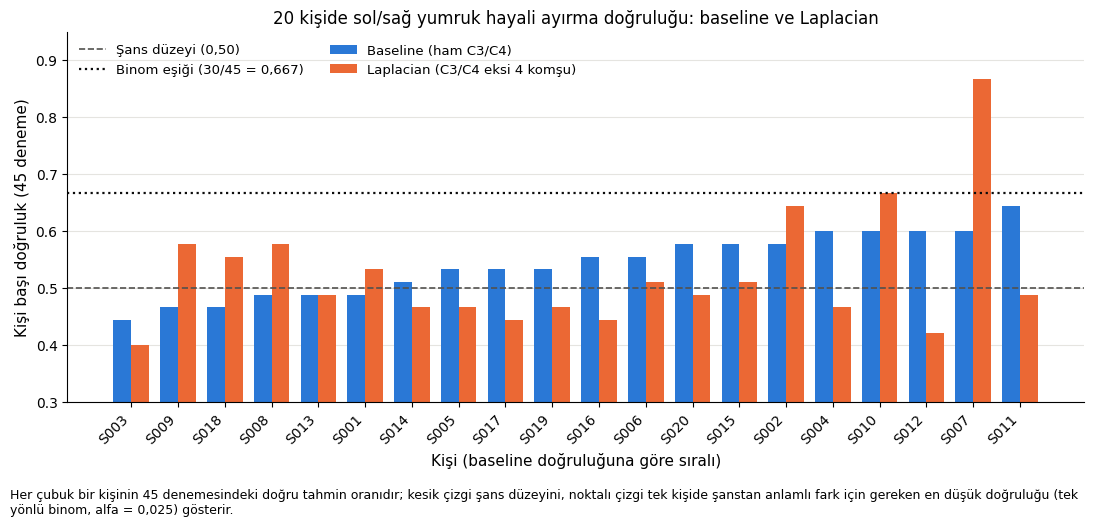

Eşiği geçen kişi | baseline: 0 | Laplacian: 2
Şansın altında kalan kişi | baseline: 6 | Laplacian: 11


In [7]:
import matplotlib.pyplot as plt
from scipy.stats import binom

n_deneme = 45
k_esik = next(k for k in range(n_deneme + 1) if binom.sf(k - 1, n_deneme, 0.5) <= 0.025)
esik = k_esik / n_deneme
print('Binom eşiği:', k_esik, '/', n_deneme, '=', round(esik, 3))

sirali = karsilastirma.sort_values('baseline')
x = np.arange(len(sirali))
gen = 0.38

fig, ax = plt.subplots(figsize=(11, 5.2))
ax.bar(x - gen / 2, sirali['baseline'], gen, color='#2a78d6', label='Baseline (ham C3/C4)')
ax.bar(x + gen / 2, sirali['laplacian'], gen, color='#eb6834', label='Laplacian (C3/C4 eksi 4 komşu)')
ax.axhline(0.5, color='#52514e', linestyle='--', linewidth=1.2, label='Şans düzeyi (0,50)')
ax.axhline(esik, color='#0b0b0b', linestyle=':', linewidth=1.6,
           label=f'Binom eşiği ({k_esik}/{n_deneme} = {esik:.3f})'.replace('.', ','))

ax.set_xticks(x)
ax.set_xticklabels(sirali.index, rotation=45, ha='right', fontsize=10)
ax.set_xlabel('Kişi (baseline doğruluğuna göre sıralı)', fontsize=11)
ax.set_ylabel('Kişi başı doğruluk (45 deneme)', fontsize=11)
ax.set_ylim(0.3, 0.95)
ax.set_title('20 kişide sol/sağ yumruk hayali ayırma doğruluğu: baseline ve Laplacian', fontsize=12)
ax.legend(frameon=False, ncol=2, loc='upper left', fontsize=9.5)
ax.grid(axis='y', color='#e5e4e0', linewidth=0.8)
ax.set_axisbelow(True)
for kenar in ['top', 'right']:
    ax.spines[kenar].set_visible(False)

aciklama = ('Her çubuk bir kişinin 45 denemesindeki doğru tahmin oranıdır; kesik çizgi şans düzeyini, '
            'noktalı çizgi tek kişide şanstan anlamlı fark için gereken en düşük doğruluğu '
            '(tek yönlü binom, alfa = 0,025) gösterir.')
fig.text(0.01, 0.005, aciklama, fontsize=9, wrap=True)
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig('/content/drive/MyDrive/sekil_kisi_basi_dogruluk.png', dpi=150, bbox_inches='tight', pad_inches=0.15)
plt.show()

print('Eşiği geçen kişi | baseline:', (sirali['baseline'] >= esik).sum(), '| Laplacian:', (sirali['laplacian'] >= esik).sum())
print('Şansın altında kalan kişi | baseline:', (sirali['baseline'] < 0.5).sum(), '| Laplacian:', (sirali['laplacian'] < 0.5).sum())